# [3] CNN: 같은 태권도 데이터를 CNN으로 분류하고 [2] MLP와 비교

- 데이터, train/val 나누는 방법은 [2]와 똑같음 → 결과를 그대로 비교할 수 있음
- 모델: **Conv → ReLU → MaxPool** 3번 + Linear (AI개론 11차시 CIFAR-10 CNN 구조)

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [2]:
# [1] 노트북에서 만든 폴더 (폴더 이름 = 정답)
DATA_DIR = "tk_crops"

transform = transforms.Compose([
    transforms.Resize((64, 64)),                    # 128 → 64 (학습 빠르게)
    transforms.ToTensor(),                          # 0~255 → 0~1, (H,W,C) → (C,H,W)
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),   # → -1 ~ 1
])

dataset = datasets.ImageFolder(DATA_DIR, transform=transform)
classes = dataset.classes
print("클래스:", dataset.class_to_idx)
print("전체 개수:", len(dataset))

클래스: {'1_start': 0, '2_middle': 1, '3_end': 2}
전체 개수: 1197


In [3]:
# 검증 데이터는 "처음 보는 사람"으로: A040 선수 사진은 전부 val, 나머지는 train
# (같은 사람 사진이 train/val에 섞이면 사람 얼굴·옷으로 외워서 점수가 부풀 수 있음)
VAL_PERSON = "A040"
train_idx = [i for i, (path, _) in enumerate(dataset.samples) if VAL_PERSON not in os.path.basename(path)]
val_idx = [i for i, (path, _) in enumerate(dataset.samples) if VAL_PERSON in os.path.basename(path)]

train_set = Subset(dataset, train_idx)
val_set = Subset(dataset, val_idx)
print("train:", len(train_set), " val:", len(val_set))

train_loader = DataLoader(train_set, batch_size=32, shuffle=True)
val_loader = DataLoader(val_set, batch_size=32, shuffle=False)

train: 933  val: 264


In [4]:
images, labels = next(iter(train_loader))
print("images:", images.shape, " labels:", labels.shape)    # (32, 3, 64, 64)

plt.figure(figsize=(12, 3))
for i in range(8):
    img = images[i].permute(1, 2, 0) * 0.5 + 0.5      # (C,H,W) → (H,W,C), 정규화 되돌리기
    plt.subplot(1, 8, i + 1)
    plt.imshow(img)
    plt.title(classes[labels[i]], fontsize=9)
    plt.axis("off")
plt.show()

images: torch.Size([32, 3, 64, 64])  labels: torch.Size([32])


## 모델 만들기

In [5]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)    # 색 3채널 → 특징 16장
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)                              # 가로세로 절반
        self.relu = nn.ReLU()
        self.fc1 = nn.Linear(64 * 8 * 8, 128)
        self.fc2 = nn.Linear(128, 3)

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))   # (N, 3, 64, 64)  → (N, 16, 32, 32)
        x = self.pool(self.relu(self.conv2(x)))   # (N, 16, 32, 32) → (N, 32, 16, 16)
        x = self.pool(self.relu(self.conv3(x)))   # (N, 32, 16, 16) → (N, 64, 8, 8)
        x = x.view(x.size(0), -1)                 # (N, 64*8*8) = (N, 4096)
        x = self.relu(self.fc1(x))
        x = self.fc2(x)                           # (N, 3)
        return x

model = CNN().to(device)
print(model)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

CNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (relu): ReLU()
  (fc1): Linear(in_features=4096, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=3, bias=True)
)


In [6]:
# shape이 어떻게 바뀌는지 직접 확인
x = torch.randn(1, 3, 64, 64).to(device)
print("입력      :", x.shape)
x = model.pool(model.relu(model.conv1(x))); print("conv1 후  :", x.shape)
x = model.pool(model.relu(model.conv2(x))); print("conv2 후  :", x.shape)
x = model.pool(model.relu(model.conv3(x))); print("conv3 후  :", x.shape)
print("펼친 후   :", x.view(1, -1).shape)

# 파라미터 수 비교: [2] MLP는 약 640만 개
print("CNN 파라미터 수:", sum(p.numel() for p in model.parameters()))

입력      : torch.Size([1, 3, 64, 64])
conv1 후  : torch.Size([1, 16, 32, 32])
conv2 후  : torch.Size([1, 32, 16, 16])
conv3 후  : torch.Size([1, 64, 8, 8])
펼친 후   : torch.Size([1, 4096])
CNN 파라미터 수: 548387


## 학습

In [7]:
EPOCHS = 15
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

for epoch in range(EPOCHS):
    # ----- 학습 -----
    model.train()
    total_loss, correct, total = 0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()              # 1. 기울기 초기화
        outputs = model(images)            # 2. 순전파
        loss = criterion(outputs, labels)  # 3. 손실 계산
        loss.backward()                    # 4. 역전파
        optimizer.step()                   # 5. 파라미터 갱신

        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    train_loss, train_acc = total_loss / total, correct / total

    # ----- 검증 -----
    model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():                  # 검증 때는 기울기 계산 안 함
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    val_loss, val_acc = total_loss / total, correct / total

    history["train_loss"].append(train_loss); history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss); history["val_acc"].append(val_acc)
    print(f"Epoch {epoch + 1:2d} | train loss {train_loss:.4f} acc {train_acc:.4f} | val loss {val_loss:.4f} acc {val_acc:.4f}")

Epoch  1 | train loss 1.0999 acc 0.3848 | val loss 1.0952 acc 0.3333
Epoch  2 | train loss 1.0537 acc 0.4544 | val loss 0.9298 acc 0.5265
Epoch  3 | train loss 0.7896 acc 0.6238 | val loss 0.7605 acc 0.6856
Epoch  4 | train loss 0.6224 acc 0.7395 | val loss 0.6369 acc 0.7045
Epoch  5 | train loss 0.4795 acc 0.8124 | val loss 0.5615 acc 0.7992
Epoch  6 | train loss 0.3715 acc 0.8607 | val loss 0.5080 acc 0.8030
Epoch  7 | train loss 0.2755 acc 0.8950 | val loss 0.4643 acc 0.8371
Epoch  8 | train loss 0.2293 acc 0.9025 | val loss 0.5489 acc 0.7652
Epoch  9 | train loss 0.1742 acc 0.9335 | val loss 0.5723 acc 0.7803
Epoch 10 | train loss 0.1227 acc 0.9539 | val loss 0.6721 acc 0.7500
Epoch 11 | train loss 0.1168 acc 0.9614 | val loss 0.4513 acc 0.8674
Epoch 12 | train loss 0.1216 acc 0.9539 | val loss 0.7474 acc 0.7955
Epoch 13 | train loss 0.1213 acc 0.9528 | val loss 0.5120 acc 0.8447
Epoch 14 | train loss 0.0600 acc 0.9764 | val loss 0.5742 acc 0.8068
Epoch 15 | train loss 0.0638 acc 0

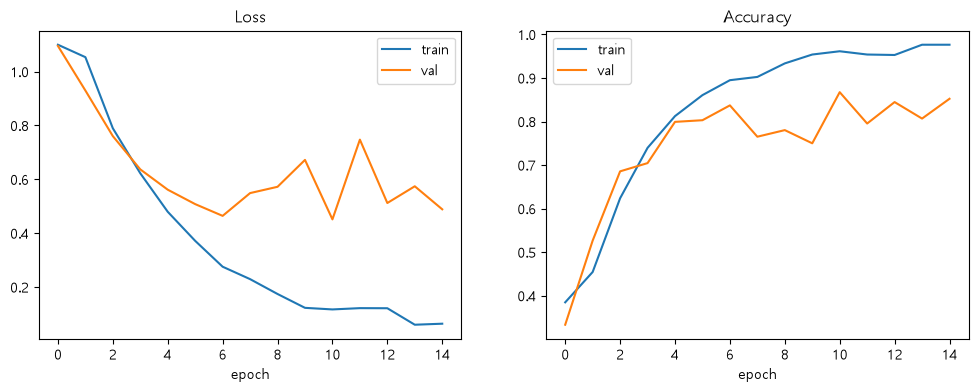

In [8]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history["train_loss"], label="train"); plt.plot(history["val_loss"], label="val")
plt.title("Loss"); plt.xlabel("epoch"); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history["train_acc"], label="train"); plt.plot(history["val_acc"], label="val")
plt.title("Accuracy"); plt.xlabel("epoch"); plt.legend()
plt.show()

## 평가

[[66 19  3]
 [ 5 76  7]
 [ 1  4 83]]


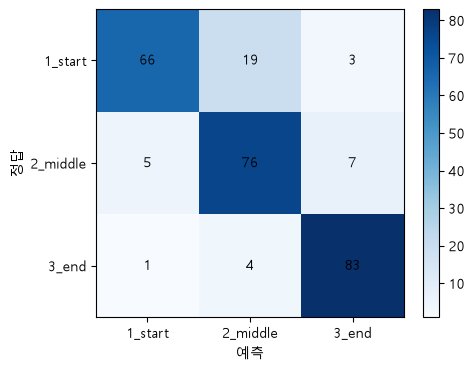

1_start    정확도: 0.75
2_middle   정확도: 0.86
3_end      정확도: 0.94


In [9]:
# 혼동행렬: 행 = 정답, 열 = 예측
all_labels, all_preds = [], []
model.eval()
with torch.no_grad():
    for images, labels in val_loader:
        outputs = model(images.to(device))
        all_preds += outputs.argmax(1).cpu().tolist()
        all_labels += labels.tolist()

cm = np.zeros((len(classes), len(classes)), dtype=int)
for t, p in zip(all_labels, all_preds):
    cm[t, p] += 1
print(cm)

plt.figure(figsize=(5, 4))
plt.imshow(cm, cmap="Blues")
plt.xticks(range(len(classes)), classes); plt.yticks(range(len(classes)), classes)
plt.xlabel("예측"); plt.ylabel("정답")
for i in range(len(classes)):
    for j in range(len(classes)):
        plt.text(j, i, cm[i, j], ha="center", va="center")
plt.colorbar(); plt.show()

for i, c in enumerate(classes):
    print(f"{c:10s} 정확도: {cm[i, i] / cm[i].sum():.2f}")

In [10]:
# val 사진 8장 예측해보기 (빨간 제목 = 틀림)
images, labels = next(iter(val_loader))
model.eval()
with torch.no_grad():
    probs = torch.softmax(model(images.to(device)), dim=1).cpu()   # 점수 → 확률
preds = probs.argmax(1)

plt.figure(figsize=(14, 3.5))
for i in range(8):
    plt.subplot(1, 8, i + 1)
    plt.imshow(images[i].permute(1, 2, 0) * 0.5 + 0.5)
    color = "black" if preds[i] == labels[i] else "red"
    plt.title(f"정답 {classes[labels[i]]}\n예측 {classes[preds[i]]}\n{probs[i, preds[i]]:.0%}", fontsize=8, color=color)
    plt.axis("off")
plt.show()

In [11]:
# conv1이 만든 특징 맵 16장 보기 (어떤 부분에 반응하는지)
img, label = val_set[0]
model.eval()
with torch.no_grad():
    fmap = model.relu(model.conv1(img.unsqueeze(0).to(device)))[0].cpu()   # (16, 64, 64)

plt.figure(figsize=(3, 3))
plt.imshow(img.permute(1, 2, 0) * 0.5 + 0.5); plt.title(classes[label]); plt.axis("off"); plt.show()

plt.figure(figsize=(12, 3))
for i in range(16):
    plt.subplot(2, 8, i + 1)
    plt.imshow(fmap[i], cmap="gray"); plt.axis("off")
plt.suptitle("conv1 특징 맵"); plt.show()

## [2] MLP와 비교해서 적어보기

| | MLP | CNN |
|---|---|---|
| 파라미터 수 | | |
| 마지막 val acc | | |
| 제일 많이 헷갈린 클래스 | | |